In [1]:
import pandas as pd
import ast
import numpy as np
import re
import os, sys
sys.path.insert(0, os.path.abspath(".."))  # project root

from functions.diagnose_utils import add_dx_features
from functions.create_plots import plot_catboost_importance

import matplotlib.pyplot as plt


In [2]:
from server_config import DATA_PATH
sys.path.append(os.path.abspath("functions"))

### 1. Therapist data

In [3]:
df_th = pd.read_csv(DATA_PATH + "/df_th_nopr_experience_corrected_200624_LB.csv", sep=";",low_memory = "False")

In [4]:
keep_cols_th = ['therapist_id', 'u_registrationDate_t','t0_method_t_CBT','t0_method_t_PDT','t0_method_t_ST','t0_method_t_AP', 't0_appliedmethod_t_VT', 't0_appliedmethod_t_TP',
             't0_appliedmethod_t_AP', 't0_appliedmethod_t_ST','t0_appliedmethod_t_Other','t0_location_t','t0_gender_t',
 't0_relationship_t','t0_sexualorientation_t','t0_children_t','t0_age_t', 't0_experience_t','t0_license_t', 't0_practice_t','t0_bfi_t_1',
 't0_bfi_t_2','t0_bfi_t_3','t0_bfi_t_4','t0_bfi_t_5','t0_bfi_t_6','t0_bfi_t_7','t0_bfi_t_8','t0_bfi_t_9','t0_bfi_t_10',]

In [5]:
labels = ["VT", "TP", "AP", "ST", "Other"]  

col = df_th["t0_appliedmethod_t_A"]

# 1) Parse strings like "[True, False, ...]" -> list
col = col.map(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# 2) Unwrap nested lists like [[True, False, ...]] -> [True, False, ...]
col = col.map(lambda x: x[0] if isinstance(x, (list, tuple)) and len(x) == 1 and isinstance(x[0], (list, tuple)) else x)

# 3) Safety: replace missing/invalid with all-False (or raise if you prefer)
def ensure_five(x):
    if isinstance(x, (list, tuple)) and len(x) == 5:
        return list(x)
    if pd.isna(x):
        return [False]*5

col = col.map(ensure_five)

# 4) Build the indicator columns
method_df = (
    pd.DataFrame(col.tolist(), index=df_th.index, columns=labels)
      .astype(int)
      .add_prefix("t0_appliedmethod_t_")
)

In [6]:
df_th = df_th.join(method_df)


In [7]:
df_th = df_th[keep_cols_th]

In [8]:
# BFI-10 items (1–5), reverse-code, then build subscale SUMS using df_th and t0-prefix
bfi_items = [f"t0_bfi_t_{i}" for i in range(1, 11)]
df_th[bfi_items] = df_th[bfi_items].apply(pd.to_numeric, errors="coerce")


# Subscale sums (2 items each)
df_th["t0_bfi_t_extraversion"]     = df_th[["t0_bfi_t_1", "t0_bfi_t_6"]].sum(axis=1)
df_th["t0_bfi_t_agreeableness"]    = df_th[["t0_bfi_t_2",   "t0_bfi_t_7"]].sum(axis=1)
df_th["t0_bfi_t_conscientiousness"]= df_th[["t0_bfi_t_3", "t0_bfi_t_8"]].sum(axis=1)
df_th["t0_bfi_t_neuroticism"]      = df_th[["t0_bfi_t_4", "t0_bfi_t_9"]].sum(axis=1)
df_th["t0_bfi_t_openness"]         = df_th[["t0_bfi_t_5", "t0_bfi_t_10"]].sum(axis=1)




### 2. Patient data

In [9]:
df_pat = pd.read_json(DATA_PATH + "/TONI_pat_corrected_20241025_raw.json")

In [10]:
df_pat_diagnose = pd.read_csv(DATA_PATH + "/patient_data_diagnosed.csv", encoding="latin1", low_memory=False)
df_pat_diagnose_short = df_pat_diagnose[["patient_id","primarydiagnosis_tp","comorbiddiagnosis_tp"]]

In [11]:
df_pat.patient_id.nunique()

1159

In [12]:
keep_cols = (
    # IDs / study
    ['patient_id', 'therapist_id', 'u_registrationDate_p'] +

    # Demographics / baseline
    ['t0_age_p','t0_gender_p','t0_school_p','t0_employment_p','t0_location_p'] +
    [f"t0_therapy_p_{i}" for i in range(1, 4)] +
    ['t0_familyhistory_p','t0_meds_p','t0_relationship_p','t0_ses_p'] +
    [f"t0_migration_p_{i}" for i in range(1, 4)] +
    [f"surveys.t0.answers.1585.discrimination_{i}" for i in range(1, 6)] +
    [f"t0_disease_p_{c}" for c in list('ABCDEFG')] +

    # t0 scales
    [f"t0_phq_p_{i}" for i in range(1, 9)] +
    [f"t0_gad_p_{i}" for i in range(1, 7+1)] +
    [f"t0_swls_p_{i}" for i in range(1, 5+1)] +
    [f"t0_aqol_p_{i}" for i in range(1, 35+1)] +
    [f"t0_ede_p_{i}" for i in range(1, 8+1)] +
    (['t0_audit_p_filter'] + [f"t0_audit_p_{i}" for i in range(1, 3+1)]) +
    (['t0_dudit_p_filter'] + [f"t0_dudit_p_{i}" for i in range(1, 4+1)]) +
    [f"t0_msfq_p_{i}" for i in range(1, 5+1)] +
    [f"t0_pid_p_{i}" for i in range(1, 36+1)] +
    [f"t0_opd_p_{i}" for i in range(1, 12+1)] +
    [f"t0_ace_p_{i}" for i in range(1, 10+1)] +
    [f"t0_ask_p_{i}" for i in range(1, 3+1)] +
    [f"t0_mhse_p_{i}" for i in range(1, 6+1)] +

    # t1 scales
    [f"t1_phq_p_{i}" for i in range(1, 8+1)] +
    [f"t1_gad_p_{i}" for i in range(1, 7+1)] +
    [f"t1_multi_p_{i}" for i in range(1, 7+1)] +
    [f"t1_cpps_p_{i}" for i in range(1, 20+1)] +

    # t2 scales
    [f"t2_phq_p_{i}" for i in range(1, 8+1)] +
    [f"t2_gad_p_{i}" for i in range(1, 7+1)] +

    
    # t3 scales
    [f"t3_phq_p_{i}" for i in range(1, 8+1)] +
    [f"t3_gad_p_{i}" for i in range(1, 7+1)] +


    # alliance / matching
    [f"t1_wai_p_{i}" for i in range(1, 12+1)]+
    [ 't0_change_p_1', 't0_change_p_2', 't0_dropout_p']+
    ["t1_matching_tp_1"]

)


In [13]:
df_pat= df_pat[keep_cols]

In [14]:
df_pat.patient_id.nunique()

1159

#### 2.1 Calculate Subscales for self-report data

#### Outcome (PHQ + GAD)

In [15]:
# define item columns
phq_cols_t1 = [f"t1_phq_p_{i}" for i in range(1, 9)]
gad_cols_t1 = [f"t1_gad_p_{i}" for i in range(1, 8)]

mask_complete = df_pat[phq_cols_t1 + gad_cols_t1].notna().all(axis=1)
df_pat_clean = df_pat.loc[mask_complete].copy()

In [16]:
df_pat_clean.patient_id.nunique()

966

In [17]:
df_pat_clean["t1_phq8_total"] = df_pat_clean[phq_cols_t1].sum(axis=1)
df_pat_clean["t1_gad7_total"] = df_pat_clean[gad_cols_t1].sum(axis=1)

In [18]:
df_pat_clean["t1_distress_sum"] = (
    df_pat_clean["t1_phq8_total"] + df_pat_clean["t1_gad7_total"]
)

In [19]:
# define item columns
phq_cols_t0 = [f"t0_phq_p_{i}" for i in range(1, 9)]
gad_cols_t0 = [f"t0_gad_p_{i}" for i in range(1, 8)]

In [20]:
df_pat_clean["t0_phq8_p_sum"] = df_pat_clean[phq_cols_t0].sum(axis=1)
df_pat_clean["t0_gad7_p_sum"] = df_pat_clean[gad_cols_t0].sum(axis=1)

In [21]:
df_pat_clean["t0_distress_sum"] = (
    df_pat_clean["t0_phq8_p_sum"] + df_pat_clean["t0_gad7_p_sum"]
)

#### SWLS Baseline

In [22]:
swls_cols_t0 = [f"t0_swls_p_{i}" for i in range(1, 6)]

In [23]:
df_pat_clean["t0_swls_p_sum"] = df_pat_clean[swls_cols_t0].sum(axis=1)

#### Aqol Baseline

In [24]:
aqol_map = {
    "t0_aqol_p_coping": ['t0_aqol_p_1', 't0_aqol_p_21', 't0_aqol_p_29'],
    "t0_aqol_p_relationship": ['t0_aqol_p_2', 't0_aqol_p_4', 't0_aqol_p_9', 't0_aqol_p_10',
                               't0_aqol_p_23', 't0_aqol_p_31', 't0_aqol_p_34'],
    "t0_aqol_p_independent_living": ['t0_aqol_p_3', 't0_aqol_p_15', 't0_aqol_p_19', 't0_aqol_p_30'],
    "t0_aqol_p_mental_health": ['t0_aqol_p_5', 't0_aqol_p_8', 't0_aqol_p_12', 't0_aqol_p_14',
                                't0_aqol_p_16', 't0_aqol_p_18', 't0_aqol_p_33', 't0_aqol_p_35'],
    "t0_aqol_p_pain": ['t0_aqol_p_6', 't0_aqol_p_22', 't0_aqol_p_24'],
    "t0_aqol_p_self_worth": ['t0_aqol_p_7', 't0_aqol_p_13', 't0_aqol_p_26'],
    "t0_aqol_p_happiness": ['t0_aqol_p_17', 't0_aqol_p_20', 't0_aqol_p_25', 't0_aqol_p_27'],
    "t0_aqol_p_senses": ['t0_aqol_p_11', 't0_aqol_p_28', 't0_aqol_p_32'],
}

In [25]:
df_pat_clean = df_pat_clean.assign(**{scale: df_pat_clean[items].mean(axis=1) for scale, items in aqol_map.items()})


#### EDE Baseline

In [26]:
df_pat_clean["t0_ede_p_sum"] = df_pat_clean[[f"t0_ede_p_{i}" for i in range(1, 9)]].sum(axis=1)


#### Audit Baseline

In [27]:
aud_items = [f"t0_audit_p_{i}" for i in range(1, 5)]
fcol = "t0_audit_p_filter"

# set all AUDIT item columns to 0 if filter == 0
df_pat_clean.loc[df_pat_clean[fcol].eq(0), aud_items] = 0

# sum AUDIT items only if filter == 1; otherwise set total to 0
df_pat_clean["t0_audit_p_sum"] = np.where(
    df_pat_clean[fcol].eq(1),
    df_pat_clean[aud_items].sum(axis=1),
    0
)

#### Dudit Baseline

In [28]:
dud_items = [f"t0_dudit_p_{i}" for i in range(1, 5)]
fcol = "t0_dudit_p_filter"

# set all AUDIT item columns to 0 if filter == 0
df_pat_clean.loc[df_pat_clean[fcol].eq(0), dud_items] = 0

# sum AUDIT items only if filter == 1; otherwise set total to 0
df_pat_clean["t0_dudit_p_sum"] = np.where(
    df_pat_clean[fcol].eq(1),
    df_pat_clean[dud_items].sum(axis=1),
    0
)

#### MFSQ Baseline

In [29]:
msfq_cols = [f"t0_msfq_p_{i}" for i in range(1, 6)]
df_pat_clean[msfq_cols] = df_pat_clean[msfq_cols].apply(pd.to_numeric, errors="coerce")

df_pat_clean["t0_msfq_p_sum"] = df_pat_clean[msfq_cols].sum(axis=1)

#### PID5BF+ Baseline

In [30]:

# PID-5 BF+ domains → item columns
pid_map = {
    "t0_pid_p_negative_affect": ['t0_pid_p_1','t0_pid_p_7','t0_pid_p_13','t0_pid_p_19','t0_pid_p_25','t0_pid_p_31'],
    "t0_pid_p_antagonism":      ['t0_pid_p_2','t0_pid_p_8','t0_pid_p_14','t0_pid_p_20','t0_pid_p_26','t0_pid_p_32'],
    "t0_pid_p_disinhibition":   ['t0_pid_p_3','t0_pid_p_9','t0_pid_p_15','t0_pid_p_21','t0_pid_p_27','t0_pid_p_33'],
    "t0_pid_p_detachment":      ['t0_pid_p_4','t0_pid_p_10','t0_pid_p_16','t0_pid_p_22','t0_pid_p_28','t0_pid_p_34'],
    "t0_pid_p_psychoticism":    ['t0_pid_p_5','t0_pid_p_11','t0_pid_p_17','t0_pid_p_23','t0_pid_p_29','t0_pid_p_35'],
    "t0_pid_p_anankastia":      ['t0_pid_p_6','t0_pid_p_12','t0_pid_p_18','t0_pid_p_24','t0_pid_p_30','t0_pid_p_36'],
}

# 1) Coerce all PID item columns to numeric (e.g., "2" → 2, invalid → NaN)
item_cols = sorted({c for cols in pid_map.values() for c in cols})
df_pat_clean[item_cols] = df_pat_clean[item_cols].apply(pd.to_numeric, errors="coerce")

# 2) Domain sums (NaNs treated as 0 by default)
for scale, items in pid_map.items():
    df_pat_clean[scale] = df_pat_clean[items].mean(axis=1)


#### OPD Baseline

In [31]:
# OPD-SFK domains → item columns
opd_map = {
    "t0_opd_p_self":         ['t0_opd_p_1', 't0_opd_p_2', 't0_opd_p_5', 't0_opd_p_8'],
    "t0_opd_p_contact":      ['t0_opd_p_4', 't0_opd_p_6', 't0_opd_p_10', 't0_opd_p_11'],
    "t0_opd_p_relationship": ['t0_opd_p_3', 't0_opd_p_7', 't0_opd_p_9', 't0_opd_p_12'],
}

# coerce item columns to numeric (e.g., "2" → 2; invalid → NaN)
opd_items = sorted({c for cols in opd_map.values() for c in cols})
df_pat_clean[opd_items] = df_pat_clean[opd_items].apply(pd.to_numeric, errors="coerce")

# domain sums (NaNs treated as 0 by default)
for scale, items in opd_map.items():
    df_pat_clean[scale] = df_pat_clean[items].mean(axis=1)

#### ACE Baseline

In [32]:
ace_cols = [f"t0_ace_p_{i}" for i in range(1, 11)]

# ensure numeric (e.g., "1" -> 1; invalid -> NaN)
df_pat_clean[ace_cols] = df_pat_clean[ace_cols].apply(pd.to_numeric, errors="coerce")

df_pat_clean["t0_ace_p_sum"] = df_pat_clean[ace_cols].sum(axis=1)

/tmp/ipykernel_87880/1448277295.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pat_clean["t0_ace_p_sum"] = df_pat_clean[ace_cols].sum(axis=1)


#### ASK Baseline

In [33]:
ask_cols = [f"t0_ask_p_{i}" for i in range(1, 4)]
df_pat_clean[ask_cols] = df_pat_clean[ask_cols].apply(pd.to_numeric, errors="coerce")

df_pat_clean["t0_ask_p_sum"] = df_pat_clean[ask_cols].sum(axis=1)

/tmp/ipykernel_87880/3480057311.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pat_clean["t0_ask_p_sum"] = df_pat_clean[ask_cols].sum(axis=1)


#### MHSE Baseline

In [34]:
mhse_cols = [f"t0_mhse_p_{i}" for i in range(1, 7)]
df_pat_clean[mhse_cols] = df_pat_clean[mhse_cols].apply(pd.to_numeric, errors="coerce")

df_pat_clean["t0_mhse_p_sum"] = df_pat_clean[mhse_cols].sum(axis=1)

/tmp/ipykernel_87880/913225046.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pat_clean["t0_mhse_p_sum"] = df_pat_clean[mhse_cols].sum(axis=1)


#### Multi T1

In [35]:
# define the 7 MULTI item columns once
multi_cols = [f"t1_multi_p_{i}" for i in range(1, 8)]

# 1) ensure the same columns are numeric
df_pat_clean[multi_cols] = df_pat_clean[multi_cols].apply(pd.to_numeric, errors="coerce")

# 2) compute therapist-level means and attach as 7 new columns to every row
multi_avg = (
    df_pat_clean
    .groupby("therapist_id")[multi_cols]
    .transform("mean")
)
multi_avg.columns = [c.replace("t1_multi_p_", "multi_avg_") for c in multi_avg.columns]

# 3) append to your dataframe (now you have multi_avg_1 .. multi_avg_7)
df_pat_clean = pd.concat([df_pat_clean, multi_avg], axis=1)
df_pat_clean["multi_sum"] = df_pat_clean[["multi_avg_1", "multi_avg_2", "multi_avg_3", "multi_avg_4", "multi_avg_5","multi_avg_6","multi_avg_7"]].sum(axis=1)

#### CPPS

In [36]:
cpps_cols = [f"t1_cpps_p_{i}" for i in range(1, 21)]

df_pat_clean[cpps_cols] = df_pat_clean[cpps_cols].apply(pd.to_numeric, errors="coerce")
cpps_avg = (
    df_pat_clean
    .groupby("therapist_id")[cpps_cols]
    .transform("mean"))
cpps_avg.columns = [c.replace("t1_cpps_p_", "cpps_avg_") for c in cpps_avg.columns]
df_pat_clean = pd.concat([df_pat_clean, cpps_avg], axis=1)

df_pat_clean["tx_cpps_p_pd"] = df_pat_clean[['cpps_avg_1', 'cpps_avg_4', 'cpps_avg_5', 'cpps_avg_7',
'cpps_avg_8', 'cpps_avg_10', 'cpps_avg_13', 'cpps_avg_14', 'cpps_avg_16', 'cpps_avg_19']].sum(axis=1)

df_pat_clean["tx_cpps_p_vt"] = df_pat_clean[['cpps_avg_2', 'cpps_avg_3', 'cpps_avg_6', 'cpps_avg_9',
'cpps_avg_11', 'cpps_avg_12', 'cpps_avg_15', 'cpps_avg_17', 'cpps_avg_18', 'cpps_avg_20']].sum(axis=1)

In [37]:
df_pat_diagnose = pd.read_csv(DATA_PATH + "/patient_data_diagnosed.csv", encoding="latin1", low_memory=False)
df_pat_diagnose = df_pat_diagnose[["patient_id","primarydiagnosis_tp","comorbiddiagnosis_tp"]]

In [38]:

df_feat, uni_p, uni_c = add_dx_features(
    df_pat_diagnose,
    primary_col="primarydiagnosis_tp",
    comorbid_col="comorbiddiagnosis_tp",
    level_multihot=3,
    allowed_letters=("F",),
    primary_prefix="pdx3",
    comorbid_prefix="cdx3",
    f43_fallback="other",
    keep_lists=True,
    missing_label="Missing",
    multihot_dtype=np.int8,   # numeric 0/1
)

# # sanity checks
print(df_feat[["primary_dx_icd10_3","primary_dx_table2"]].head())
mh_cols = [c for c in df_feat.columns if c.startswith(("pdx3_", "cdx3_"))]

  primary_dx_icd10_3    primary_dx_table2
0                F32  Affective disorders
1                F32  Affective disorders
2                F32  Affective disorders
3                F32  Affective disorders
4                F32  Affective disorders


In [39]:
print(df_feat[mh_cols].isna().sum().sum(), "total NaNs in multihot")  # should be 0
print(df_feat[["primary_count","n_comorbid"]].dtypes)

0 total NaNs in multihot
primary_count    int64
n_comorbid       int64
dtype: object


In [40]:
df_feat = df_feat.drop_duplicates(subset="patient_id")

In [41]:
df_all = pd.merge(df_pat_clean, df_feat, on="patient_id", how= "left")

In [42]:
df_all = pd.merge(df_pat_clean, df_feat, on="patient_id", how="left")

mh_cols = [c for c in df_feat.columns if c.startswith(("pdx3_", "cdx3_"))]
df_all[mh_cols] = df_all[mh_cols].fillna(0).astype(np.int8)

In [43]:
df_all.patient_id.nunique()

966

In [44]:
df_feat.pdx3_F10.unique()

array([0, 1], dtype=int8)

In [45]:
df_all.pdx3_F10.unique()

array([0, 1], dtype=int8)

### Intake 

### Concatenate patient and therapist df

In [46]:
df_all = pd.merge(df_all, df_th, on="therapist_id", how= "left", validate="many_to_one")

In [47]:
df_all.patient_id.nunique()

966

In [48]:
df_all["u_registrationDate_p_datetime"] = pd.to_datetime(
    df_all["u_registrationDate_p"], errors="coerce", dayfirst=True, utc=True
)
iso = df_all["u_registrationDate_p_datetime"].dt.isocalendar()
df_all["intake_week"]  = iso.week.astype("Int64")
df_all["intake_month"] = df_all["u_registrationDate_p_datetime"].dt.month.astype("Int64")
df_all["intake_year"]  = df_all["u_registrationDate_p_datetime"].dt.year.astype("Int64").astype("string")

In [49]:
patient_numeric=['t0_age_p', 't0_ses_p', 'surveys.t0.answers.1585.discrimination_1', 'surveys.t0.answers.1585.discrimination_2',
 'surveys.t0.answers.1585.discrimination_3', 'surveys.t0.answers.1585.discrimination_4', 'surveys.t0.answers.1585.discrimination_5',
  't0_phq_p_1', 't0_phq_p_2', 't0_phq_p_3', 't0_phq_p_4', 't0_phq_p_5', 't0_phq_p_6', 't0_phq_p_7', 't0_phq_p_8',
 't0_gad_p_1', 't0_gad_p_2', 't0_gad_p_3', 't0_gad_p_4', 't0_gad_p_5', 't0_gad_p_6', 't0_gad_p_7','t0_swls_p_1',
 't0_swls_p_2', 't0_swls_p_3', 't0_swls_p_4', 't0_swls_p_5', 't0_aqol_p_1','t0_aqol_p_2', 't0_aqol_p_3',
 't0_aqol_p_4', 't0_aqol_p_5', 't0_aqol_p_6', 't0_aqol_p_7', 't0_aqol_p_8', 't0_aqol_p_9', 't0_aqol_p_10',
 't0_aqol_p_11', 't0_aqol_p_12', 't0_aqol_p_13', 't0_aqol_p_14', 't0_aqol_p_15', 't0_aqol_p_16', 't0_aqol_p_17',
 't0_aqol_p_18', 't0_aqol_p_19', 't0_aqol_p_20', 't0_aqol_p_21', 't0_aqol_p_22', 't0_aqol_p_23', 't0_aqol_p_24',
 't0_aqol_p_25', 't0_aqol_p_26', 't0_aqol_p_27', 't0_aqol_p_28', 't0_aqol_p_29', 't0_aqol_p_30', 't0_aqol_p_31',
 't0_aqol_p_32', 't0_aqol_p_33', 't0_aqol_p_34', 't0_aqol_p_35', 't0_audit_p_1', 't0_audit_p_2', 't0_audit_p_3',
  't0_dudit_p_1', 't0_dudit_p_2', 't0_dudit_p_3', 't0_dudit_p_4', 't0_msfq_p_1', 't0_msfq_p_2', 't0_msfq_p_3',
 't0_msfq_p_4', 't0_msfq_p_5', 't0_pid_p_1', 't0_pid_p_2', 't0_pid_p_3', 't0_pid_p_4', 't0_pid_p_5', 't0_pid_p_6',
 't0_pid_p_7', 't0_pid_p_8', 't0_pid_p_9', 't0_pid_p_10', 't0_pid_p_11', 't0_pid_p_12', 't0_pid_p_13', 't0_pid_p_14',
 't0_pid_p_15', 't0_pid_p_16', 't0_pid_p_17', 't0_pid_p_18', 't0_pid_p_19', 't0_pid_p_20', 't0_pid_p_21',
 't0_pid_p_22', 't0_pid_p_23', 't0_pid_p_24', 't0_pid_p_25', 't0_pid_p_26', 't0_pid_p_27', 't0_pid_p_28',
 't0_pid_p_29', 't0_pid_p_30', 't0_pid_p_31', 't0_pid_p_32', 't0_pid_p_33', 't0_pid_p_34', 't0_pid_p_35',
 't0_pid_p_36', 't0_opd_p_1', 't0_opd_p_2', 't0_opd_p_3', 't0_opd_p_4', 't0_opd_p_5', 't0_opd_p_6', 't0_opd_p_7',
 't0_opd_p_8', 't0_opd_p_9', 't0_opd_p_10', 't0_opd_p_11', 't0_opd_p_12', 't0_ace_p_1', 't0_ace_p_2',
 't0_ace_p_3', 't0_ace_p_4', 't0_ace_p_5', 't0_ace_p_6', 't0_ace_p_7', 't0_ace_p_8', 't0_ace_p_9', 't0_ace_p_10',
 't0_ask_p_1', 't0_ask_p_2', 't0_ask_p_3', 't0_mhse_p_1', 't0_mhse_p_2', 't0_mhse_p_3', 't0_mhse_p_4', 't0_mhse_p_5',
 't0_mhse_p_6', 't0_change_p_1', 't0_change_p_2', 't0_dropout_p', 't0_phq8_p_sum', 't0_gad7_p_sum', 't0_swls_p_sum',
 't0_aqol_p_coping','t0_aqol_p_relationship', 't0_aqol_p_independent_living', 't0_aqol_p_mental_health',
 't0_aqol_p_pain', 't0_aqol_p_self_worth', 't0_aqol_p_happiness', 't0_aqol_p_senses', 't0_audit_p_sum',
 't0_dudit_p_sum', 't0_msfq_p_sum', 't0_pid_p_negative_affect', 't0_pid_p_antagonism', 't0_pid_p_disinhibition',
 't0_pid_p_detachment', 't0_pid_p_psychoticism', 't0_pid_p_anankastia', 't0_opd_p_self', 't0_opd_p_contact',
 't0_opd_p_relationship', 't0_ace_p_sum', 't0_ask_p_sum', 't0_mhse_p_sum']

patient_categorical=['t0_gender_p', 't0_school_p', 't0_employment_p', 't0_location_p', 't0_therapy_p_1', 't0_therapy_p_2',
 't0_familyhistory_p', 't0_meds_p', 't0_relationship_p', 't0_migration_p_1',
 't0_migration_p_2', 't0_migration_p_3', 't0_disease_p_A', 't0_disease_p_B', 't0_disease_p_C',
 't0_disease_p_D', 't0_disease_p_E', 't0_disease_p_F', 't0_disease_p_G']

In [50]:
miss_summary = (df_all[patient_numeric + patient_categorical]
                .isna()
                .sum()
                .rename("n_nan")
                .to_frame())
miss_summary["pct_nan"] = miss_summary["n_nan"] / len(df_all) * 100
miss_summary.sort_values("pct_nan", ascending=False).head(20)


,n_nan,pct_nan
t0_pid_p_23,309,31.987578
t0_pid_p_24,309,31.987578
t0_pid_p_25,309,31.987578
t0_pid_p_26,309,31.987578
t0_pid_p_27,309,31.987578
t0_pid_p_28,309,31.987578
t0_pid_p_29,309,31.987578
t0_pid_p_30,309,31.987578
t0_pid_p_31,309,31.987578
t0_pid_p_32,309,31.987578


In [51]:
therapist_numeric = [
        't0_age_t','t0_experience_t','t0_bfi_t_1','t0_bfi_t_2','t0_bfi_t_3','t0_bfi_t_4','t0_bfi_t_5',
        't0_bfi_t_6','t0_bfi_t_7','t0_bfi_t_8','t0_bfi_t_9','t0_bfi_t_10',
        't0_bfi_t_extraversion','t0_bfi_t_agreeableness','t0_bfi_t_conscientiousness',
        't0_bfi_t_neuroticism','t0_bfi_t_openness'
    ]
therapist_categorical = [
        't0_method_t_CBT','t0_method_t_PDT','t0_method_t_ST','t0_method_t_AP',
        't0_appliedmethod_t_VT','t0_appliedmethod_t_TP','t0_appliedmethod_t_AP',
        't0_appliedmethod_t_ST','t0_appliedmethod_t_Other',
        't0_location_t','t0_gender_t','t0_relationship_t','t0_sexualorientation_t','t0_children_t','t0_practice_t'
    ]

In [52]:
miss_summary = (df_all[therapist_numeric + therapist_categorical]
                .isna()
                .sum()
                .rename("n_nan")
                .to_frame())
miss_summary["pct_nan"] = miss_summary["n_nan"] / len(df_all) * 100
miss_summary.sort_values("pct_nan", ascending=False).head(20)


,n_nan,pct_nan
t0_practice_t,966,100.000000
t0_age_t,9,0.931677
t0_bfi_t_1,9,0.931677
t0_experience_t,9,0.931677
t0_bfi_t_3,9,0.931677
t0_bfi_t_4,9,0.931677
t0_bfi_t_5,9,0.931677
t0_bfi_t_2,9,0.931677
t0_bfi_t_7,9,0.931677
t0_bfi_t_8,9,0.931677


#### Remove therapists with missing side features

In [53]:
df_all = df_all[df_all.t0_experience_t.notna()]

In [54]:
df_all.therapist_id.nunique()

174

In [55]:
df_all.patient_id.nunique()

957

In [56]:
 patient_keep= ['t0_age_p','t0_gender_p', "t0_distress_sum","t1_distress_sum",'t0_school_p', 't0_employment_p', 't0_location_p',
                't0_relationship_p', 't0_migration_p_1','t0_ses_p',
 't0_migration_p_2', 't0_migration_p_3', 't0_disease_p_A', 't0_disease_p_B', 't0_disease_p_C',
 't0_disease_p_D', 't0_disease_p_E', 't0_disease_p_F', 't0_disease_p_G', 't0_pid_p_negative_affect', 't0_pid_p_antagonism', 't0_pid_p_disinhibition',
 't0_pid_p_detachment', 't0_pid_p_psychoticism', 't0_pid_p_anankastia', 'primary_dx_table2', 'n_comorbid']

In [57]:
df_all_patients = df_all[patient_keep].copy()

In [58]:
df_all_patients.to_csv("patient_data.csv", index=False)

In [59]:
df_all.t0_distress_sum.describe()

count    957.000000
mean      23.600836
std        8.910264
min        0.000000
25%       17.000000
50%       23.000000
75%       30.000000
max       45.000000
Name: t0_distress_sum, dtype: float64

In [60]:
df_all.t1_distress_sum.describe()

count    957.000000
mean      19.637409
std        8.684448
min        0.000000
25%       13.000000
50%       19.000000
75%       26.000000
max       45.000000
Name: t1_distress_sum, dtype: float64

In [61]:
miss_summary = (df_all[patient_numeric + patient_categorical]
                .isna()
                .sum()
                .rename("n_nan")
                .to_frame())
miss_summary["pct_nan"] = miss_summary["n_nan"] / len(df_all) * 100
miss_summary.sort_values("pct_nan", ascending=False).head(20)


,n_nan,pct_nan
t0_pid_p_23,309,32.288401
t0_pid_p_24,309,32.288401
t0_pid_p_25,309,32.288401
t0_pid_p_26,309,32.288401
t0_pid_p_27,309,32.288401
t0_pid_p_28,309,32.288401
t0_pid_p_29,309,32.288401
t0_pid_p_30,309,32.288401
t0_pid_p_31,309,32.288401
t0_pid_p_32,309,32.288401


#### Mark age as missing

In [62]:
mask_bad_age = df_all["t0_age_t"].notna() & (df_all["t0_age_t"] < 23)
n_bad = int(mask_bad_age.sum())
print(f"[repair] t0_age_t: setting {n_bad} implausible values (<23) to NaN")

df_all.loc[mask_bad_age, "t0_age_t"] = np.nan


[repair] t0_age_t: setting 92 implausible values (<23) to NaN


### Data export

In [63]:
df_all.to_csv(DATA_PATH + "/toni_preprocessed.csv")

### 2.2 Run Model

In [ ]:
from ML_Pipeline_CLEAR_final import MatchConfig, run_pipeline

cfg = MatchConfig(
    PATIENT_ID_COL="patient_id",
    THERAPIST_ID_COL="therapist_id",
    DATE_COL="u_registrationDate_p",
    DATE_DAYFIRST=True,
    DATE_FORMAT=None,
    

    LABEL_COL="t1_distress_sum",
    STANDARDIZE_Y=True,
    CAT_USE_NATIVE_CATEGORICAL=True,
    CAT_MIN_FREQ_FOR_OHE=1,
    RUN_MODELS = ["cat"],
    CAT_NATIVE_HANDLE_MISSING = True,


    patient_numeric = [
    't0_ses_p','surveys.t0.answers.1585.discrimination_1','surveys.t0.answers.1585.discrimination_2',
    'surveys.t0.answers.1585.discrimination_3','surveys.t0.answers.1585.discrimination_4','surveys.t0.answers.1585.discrimination_5',
    't0_phq_p_1','t0_phq_p_2','t0_phq_p_3','t0_phq_p_4','t0_phq_p_5','t0_phq_p_6','t0_phq_p_7','t0_phq_p_8',
    't0_gad_p_1','t0_gad_p_2','t0_gad_p_3','t0_gad_p_4','t0_gad_p_5','t0_gad_p_6','t0_gad_p_7',
    't0_swls_p_1','t0_swls_p_2','t0_swls_p_3','t0_swls_p_4','t0_swls_p_5',
    't0_aqol_p_1','t0_aqol_p_2','t0_aqol_p_3','t0_aqol_p_4','t0_aqol_p_5','t0_aqol_p_6','t0_aqol_p_7','t0_aqol_p_8','t0_aqol_p_9','t0_aqol_p_10',
    't0_aqol_p_11','t0_aqol_p_12','t0_aqol_p_13','t0_aqol_p_14','t0_aqol_p_15','t0_aqol_p_16','t0_aqol_p_17',
    't0_aqol_p_18','t0_aqol_p_19','t0_aqol_p_20','t0_aqol_p_21','t0_aqol_p_22','t0_aqol_p_23','t0_aqol_p_24','t0_aqol_p_25','t0_aqol_p_26',
    't0_aqol_p_27','t0_aqol_p_28','t0_aqol_p_29','t0_aqol_p_30','t0_aqol_p_31','t0_aqol_p_32','t0_aqol_p_33','t0_aqol_p_34','t0_aqol_p_35',
    't0_audit_p_1','t0_audit_p_2','t0_audit_p_3',
    't0_dudit_p_1','t0_dudit_p_2','t0_dudit_p_3','t0_dudit_p_4',
    't0_msfq_p_1','t0_msfq_p_2','t0_msfq_p_3','t0_msfq_p_4','t0_msfq_p_5',
    't0_pid_p_1','t0_pid_p_2','t0_pid_p_3','t0_pid_p_4','t0_pid_p_5','t0_pid_p_6','t0_pid_p_7','t0_pid_p_8','t0_pid_p_9','t0_pid_p_10',
    't0_pid_p_11','t0_pid_p_12','t0_pid_p_13','t0_pid_p_14','t0_pid_p_15','t0_pid_p_16','t0_pid_p_17','t0_pid_p_18','t0_pid_p_19','t0_pid_p_20',
    't0_pid_p_21','t0_pid_p_22','t0_pid_p_23','t0_pid_p_24','t0_pid_p_25','t0_pid_p_26','t0_pid_p_27','t0_pid_p_28','t0_pid_p_29','t0_pid_p_30',
    't0_pid_p_31','t0_pid_p_32','t0_pid_p_33','t0_pid_p_34','t0_pid_p_35','t0_pid_p_36',
    't0_opd_p_1','t0_opd_p_2','t0_opd_p_3','t0_opd_p_4','t0_opd_p_5','t0_opd_p_6','t0_opd_p_7','t0_opd_p_8','t0_opd_p_9','t0_opd_p_10','t0_opd_p_11','t0_opd_p_12',
    't0_ace_p_1','t0_ace_p_2','t0_ace_p_3','t0_ace_p_4','t0_ace_p_5','t0_ace_p_6','t0_ace_p_7','t0_ace_p_8','t0_ace_p_9','t0_ace_p_10',
    't0_ask_p_1','t0_ask_p_2','t0_ask_p_3',
    't0_mhse_p_1','t0_mhse_p_2','t0_mhse_p_3','t0_mhse_p_4','t0_mhse_p_5','t0_mhse_p_6',
    't0_change_p_1','t0_change_p_2','t0_dropout_p',
    't0_phq8_p_sum','t0_gad7_p_sum','t0_swls_p_sum',
    't0_aqol_p_coping','t0_aqol_p_relationship','t0_aqol_p_independent_living','t0_aqol_p_mental_health',
    't0_aqol_p_pain','t0_aqol_p_self_worth','t0_aqol_p_happiness','t0_aqol_p_senses',
    't0_audit_p_sum','t0_dudit_p_sum','t0_msfq_p_sum',
    't0_pid_p_negative_affect','t0_pid_p_antagonism','t0_pid_p_disinhibition','t0_pid_p_detachment','t0_pid_p_psychoticism','t0_pid_p_anankastia',
    't0_opd_p_self','t0_opd_p_contact','t0_opd_p_relationship',
    't0_ace_p_sum','t0_ask_p_sum','t0_mhse_p_sum','t0_age_p',
    ],
    patient_categorical = [
        't0_gender_p','t0_school_p','t0_employment_p','t0_location_p',
        't0_therapy_p_1','t0_therapy_p_2','t0_familyhistory_p','t0_meds_p',
        't0_relationship_p','t0_migration_p_1','t0_migration_p_2','t0_migration_p_3',
        't0_disease_p_A','t0_disease_p_B','t0_disease_p_C','t0_disease_p_D',
        't0_disease_p_E','t0_disease_p_F','t0_disease_p_G', 
   
        
    ],
    therapist_numeric = [
        't0_age_t','t0_experience_t','t0_bfi_t_1','t0_bfi_t_2','t0_bfi_t_3','t0_bfi_t_4','t0_bfi_t_5',
        't0_bfi_t_6','t0_bfi_t_7','t0_bfi_t_8','t0_bfi_t_9','t0_bfi_t_10',
        't0_bfi_t_extraversion','t0_bfi_t_agreeableness','t0_bfi_t_conscientiousness',
        't0_bfi_t_neuroticism','t0_bfi_t_openness', 
       
    ],
    therapist_categorical = [
        't0_method_t_CBT','t0_method_t_PDT','t0_method_t_ST','t0_method_t_AP',
        't0_appliedmethod_t_VT','t0_appliedmethod_t_TP','t0_appliedmethod_t_AP',
        't0_appliedmethod_t_ST','t0_appliedmethod_t_Other',
        't0_location_t','t0_gender_t','t0_children_t', 't0_relationship_t','t0_sexualorientation_t',

    ], 
    impute_strategy = "median",
    # --- Baseline-capacity neighborhood around your current best ---
    cat_param_grid = [
    # fast / higher lr
    {
        "regressor__learning_rate": [0.1],
        "regressor__iterations": [300], #300
        "regressor__depth": [6, 8],
        "regressor__l2_leaf_reg": [3.0, 10.0],
    },
    # medium
    {
        "regressor__learning_rate": [0.06],
        "regressor__iterations": [600],
        "regressor__depth": [6, 8],
        "regressor__l2_leaf_reg": [3.0, 10.0],
    },
    # slower / lower lr
    {
        "regressor__learning_rate": [0.03],
        "regressor__iterations": [1000],
        "regressor__depth": [6, 8],
        "regressor__l2_leaf_reg": [3.0, 10.0],
    },
],


    EXPLAIN_COMPUTE_SHAP_GLOBAL=True,
    EXPLAIN_COMPUTE_SHAP_INTERACTIONS=True,
)


In [65]:
results = run_pipeline(df_all, cfg)
results["summary"]


2026-02-24 16:19:04,750 [INFO] Match_Pipeline: date: parsing 'u_registrationDate_p' (dayfirst=True, format=None)


2026-02-24 16:19:05,331 [INFO] Match_Pipeline: Therapists: 174 | Train: 656 | Val: 142 | Test: 159 | repeat=0 | CV=per_therapist_random | RUN_MODELS=['cat']
2026-02-24 16:19:05,333 [INFO] Match_Pipeline: candidates: 174 therapists in train
2026-02-24 16:19:05,354 [INFO] Match_Pipeline: [Fitting] cat
Fitting 1 folds for each of 12 candidates, totalling 12 fits
[CV] END regressor__regressor__depth=6, regressor__regressor__iterations=300, regressor__regressor__l2_leaf_reg=3.0, regressor__regressor__learning_rate=0.1; total time=   2.9s
[CV] END regressor__regressor__depth=6, regressor__regressor__iterations=300, regressor__regressor__l2_leaf_reg=10.0, regressor__regressor__learning_rate=0.1; total time=   2.8s
[CV] END regressor__regressor__depth=8, regressor__regressor__iterations=300, regressor__regressor__l2_leaf_reg=3.0, regressor__regressor__learning_rate=0.1; total time=   4.3s
[CV] END regressor__regressor__depth=8, regressor__regressor__iterations=300, regressor__regressor__l2_lea

/home/leha18/.conda/envs/torchenv/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


,model,n_runs,val_mean,val_sd,val_min,val_max,test_mean,test_sd,test_min,test_max,selected_as_best_count
0,patient_only_cat,5,6.238460,0.206012,5.969426,6.538850,6.289035,0.215666,6.007926,6.510208,0
1,cat,5,6.232211,0.228193,5.915437,6.541551,6.326901,0.236761,5.997249,6.558441,5
2,naive_mean,5,8.434676,0.628062,7.472666,9.226401,8.509773,0.406673,8.084440,8.930873,0


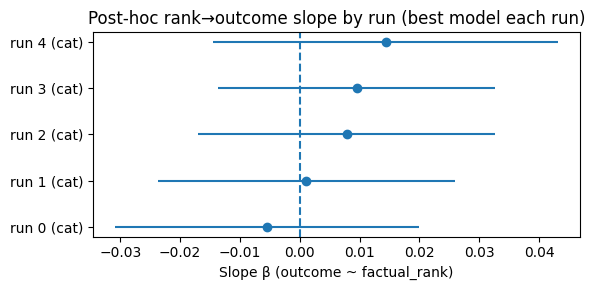

In [66]:


df = results["cv_posthoc_best_by_run"].copy()
df["ci_low"] = df["beta"] - 1.96 * df["se"]
df["ci_high"] = df["beta"] + 1.96 * df["se"]

df = df.sort_values("beta").reset_index(drop=True)
ypos = np.arange(len(df))

plt.figure(figsize=(6, max(3, 0.25 * len(df))))
plt.errorbar(df["beta"], ypos, xerr=[df["beta"]-df["ci_low"], df["ci_high"]-df["beta"]], fmt="o")
plt.axvline(0, linestyle="--")
plt.yticks(ypos, [f'run {r} ({m})' for r, m in zip(df["run"], df["best_model"])])
plt.xlabel("Slope β (outcome ~ factual_rank)")
plt.title("Post-hoc rank→outcome slope by run (best model each run)")
plt.tight_layout()
plt.show()
